# Ablation V1 — CNN-Only Baseline (EfficientNet-B4)

## Prostate Cancer Detection · H&E Histopathology (DiagSet Binary)

**Journal Retrain — matched to Hybrid / LGCN / GAT / JGCN retrain protocol**

Purpose of V1: measure the standalone contribution of the CNN backbone before any graph-branch or fusion mechanism is added. All later ablation variants (V2–V5) build on top of this baseline under the identical training protocol.

- **Architecture**: EfficientNet-B4 (blocks 0-4 frozen, 5-7 fine-tuned) → cnn_proj (1792 → 512-dim) → classifier head (512 → 512 → 128 → 2)
- **No graph branches, no fusion gate.**
- **Local paths**: `<repo>/results\Ablation_V1\`
- **Environment**: `abide` conda env (torch 2.5.1+cu121, torchvision 0.20.1, CUDA 12.1)
- **Hardware**: RTX 3060 12 GB

**Matched protocol vs Hybrid / LGCN / GAT / JGCN**
- 80 epochs, patience 15 on validation AUC-ROC (was 80 ep / patience 15 in Hybrid retrain)
- Focal Loss (γ=2.0, α=0.75)
- AdamW differential LRs (backbone 1×10⁻⁴, head 3×10⁻⁴), weight decay 1×10⁻⁴
- CosineAnnealingWarmRestarts (T₀=10, T_mult=2)
- MixUp α=0.2 on 50% of batches, TrivialAugment, RandomErasing p=0.25
- WeightedRandomSampler, TTA×5 at inference (fp32)
- seed=42, image-level 70/15/15 stratified split (identical 901-patch test set)

**Artefacts produced (Cell 6B)**
- `v1_predictions.npz` — y_true / y_pred / y_prob (non-TTA & TTA) + 512-dim cnn_proj features
- `v1_history.json` — full epoch-by-epoch metrics
- `v1_env.json` — reproducibility fingerprint
- `checkpoints_backup/` — local copy of all four artefacts

**Fixes vs original V1 pilot notebook**
- Confirmed 80 epochs / patience 15 (matches paper's stated matched protocol)
- Full artefact save with 512-dim feature hook (for later t-SNE / feature-space analysis)
- Local backup of every artefact


## CELL 1B — Local PC Setup (RTX 3060 / abide conda env)

In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1B — Local PC Setup                                     ║
# ║   No Drive mount — reads dataset from <repo>\      ║
# ║   Saves ALL retrain artefacts to Journal Ready\Ablation_V1\  ║
# ╚══════════════════════════════════════════════════════════════╝
import os

WORK_DIR   = os.path.join(REPO_ROOT, 'runs', 'ablation_v1')
DATA_ROOT  = REPO_ROOT
DRIVE_ROOT = DATA_ROOT

os.makedirs(WORK_DIR, exist_ok=True)
assert os.path.isdir(WORK_DIR), f'Folder not found: {WORK_DIR}'

print('Work directory  :', WORK_DIR)
print('Files in folder :')
for f in sorted(os.listdir(WORK_DIR)):
    print('  •', f)


Work directory  : <repo>/results\Ablation_V1
Files in folder :


## CELL 1 — Environment check (skip if abide env already prepared)

In [2]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1 — Environment check                                   ║
# ║   V1 needs NO PyG dependency — pure PyTorch + torchvision    ║
# ╚══════════════════════════════════════════════════════════════╝
import torch, sys
print('Python  :', sys.version.split()[0])
print('Torch   :', torch.__version__)
print('CUDA    :', torch.version.cuda)
print('GPU     :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')
import torchvision
print('torchvision:', torchvision.__version__)
import timm
print('timm    :', timm.__version__)


Python  : 3.10.20
Torch   : 2.5.1+cu121
CUDA    : 12.1
GPU     : NVIDIA GeForce RTX 3060
torchvision: 0.20.1+cu121
timm    : 1.0.9


## CELL 2 — Imports and Config (LOCAL paths)

In [3]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 2 — Imports and Config (LOCAL paths — matches Hybrid)   ║
# ║   Dataset  : <repo>/dataset\{Benign, Malignant}    ║
# ║   Model    : WORK_DIR\best_v1_model.pth                      ║
# ║   V1 needs no graph cache.                                   ║
# ╚══════════════════════════════════════════════════════════════╝
import os, random, warnings, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    matthews_corrcoef, roc_curve, precision_recall_curve, average_precision_score
)
warnings.filterwarnings('ignore')

def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.cpu().numpy().transpose(1, 2, 0)
    return np.clip(img * std + mean, 0, 1)

CONFIG = {
    # ── LOCAL PATHS ──
    'data_dir'         : os.path.join(REPO_ROOT, 'dataset'),
    'output_dir'       : WORK_DIR,
    'model_save_path'  : os.path.join(WORK_DIR, 'best_v1_model.pth'),

    # ── Image ──
    'img_size'         : 224,

    # ── V1 architecture ──
    'cnn_proj_dim'     : 512,
    'head_hidden_dim'  : 128,
    'dropout'          : 0.4,
    'num_classes'      : 2,

    # ── Training (MATCHED to Hybrid / LGCN / GAT / JGCN retrain) ──
    'batch_size'       : 32,
    'num_epochs'       : 80,          # ← was 50 in original V1; now matched
    'lr_backbone'      : 1e-4,
    'lr_head'          : 3e-4,
    'weight_decay'     : 1e-4,
    'patience'         : 15,          # ← was 12 in original; now matched
    'focal_gamma'      : 2.0,
    'focal_alpha'      : 0.75,
    'seed'             : 42,
    'train_split'      : 0.70,
    'val_split'        : 0.15,
    'test_split'       : 0.15,
    'num_workers'      : 0,
    'mixup_alpha'      : 0.2,
    'mixup_prob'       : 0.5,
    'erase_prob'       : 0.25,
    'tta_n'            : 5,
    'use_amp'          : False,
}
SEED = CONFIG['seed']
MODEL_PATH = CONFIG['model_save_path']

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
os.makedirs(CONFIG['output_dir'], exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 60)
print('  ABLATION V1: CNN-ONLY BASELINE (EfficientNet-B4)')
print('  Journal Retrain — matched protocol')
print('=' * 60)
print(f'  Device      : {DEVICE}')
if torch.cuda.is_available():
    print(f'  GPU         : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM        : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
print(f'  Epochs      : {CONFIG["num_epochs"]}  |  Patience : {CONFIG["patience"]}')
print(f'  Batch       : {CONFIG["batch_size"]}')
print(f'  LR backbone : {CONFIG["lr_backbone"]}  |  LR head : {CONFIG["lr_head"]}')
print(f'  Loss        : Focal (γ={CONFIG["focal_gamma"]}, α={CONFIG["focal_alpha"]})')
print(f'  Scheduler   : CosineAnnealingWarmRestarts (T0=10, T_mult=2)')
print(f'  Model out   : {CONFIG["model_save_path"]}')
print('=' * 60)


  ABLATION V1: CNN-ONLY BASELINE (EfficientNet-B4)
  Journal Retrain — matched protocol
  Device      : cuda
  GPU         : NVIDIA GeForce RTX 3060
  VRAM        : 12.9 GB
  Epochs      : 80  |  Patience : 15
  Batch       : 32
  LR backbone : 0.0001  |  LR head : 0.0003
  Loss        : Focal (γ=2.0, α=0.75)
  Scheduler   : CosineAnnealingWarmRestarts (T0=10, T_mult=2)
  Model out   : <repo>/results\Ablation_V1\best_v1_model.pth


## CELL 3 — Dataset (no graph — CNN-only)

In [4]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 3 — Dataset + Split + Loaders                           ║
# ║   Same 70/15/15 stratified split as LGCN/GAT/JGCN            ║
# ║   (deterministic given seed=42)                              ║
# ╚══════════════════════════════════════════════════════════════╝
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

class ProstateCNNDataset(Dataset):
    def __init__(self, file_list, labels, transform):
        self.file_list = file_list
        self.labels    = labels
        self.transform = transform
    def __len__(self):
        return len(self.file_list)
    def __getitem__(self, idx):
        img = Image.open(self.file_list[idx]).convert('RGB')
        img_t = self.transform(img)
        return img_t, torch.tensor(int(self.labels[idx]), dtype=torch.long)

# ── Canonical file listing (same as baselines) ──────────────
data_dir = Path(CONFIG['data_dir'])
all_paths, all_labels = [], []
for label_idx, cls in enumerate(['Benign', 'Malignant']):
    class_dir = data_dir / cls
    files = [p for p in class_dir.iterdir() if p.suffix.lower() in IMG_EXTS]
    all_paths.extend([str(p) for p in files])
    all_labels.extend([label_idx] * len(files))
    print(f'  {cls:12s}: {len(files):5d} images')

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f'  Total       : {len(all_paths)}')

# ── Same stratified 70/15/15 split (seed=42) as LGCN/GAT/JGCN ──
idx = np.arange(len(all_paths))
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=all_labels, random_state=SEED)
val_idx, test_idx   = train_test_split(
    temp_idx, test_size=0.50,
    stratify=all_labels[temp_idx], random_state=SEED)

print(f'  Train : {len(train_idx)}   Val : {len(val_idx)}   Test : {len(test_idx)}')

# ── Transforms ─────────────────────────────────────────────
train_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(15),
    T.TrivialAugmentWide(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    T.RandomErasing(p=CONFIG['erase_prob'], scale=(0.02, 0.10), ratio=(0.3, 3.3)),
])

eval_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# TTA-5 transforms (fixed set: identity, hflip, vflip, rot90, rot270)
class TTAWrap:
    def __init__(self, base_tf):
        self.base = base_tf
    def __call__(self, img):
        return [
            self.base(img),                              # identity
            self.base(img.transpose(Image.FLIP_LEFT_RIGHT)),
            self.base(img.transpose(Image.FLIP_TOP_BOTTOM)),
            self.base(img.rotate(90)),
            self.base(img.rotate(270)),
        ]
tta_tf = TTAWrap(eval_tf)

# ── Datasets ───────────────────────────────────────────────
train_ds = ProstateCNNDataset(all_paths[train_idx].tolist(),
                               all_labels[train_idx].tolist(), train_tf)
val_ds   = ProstateCNNDataset(all_paths[val_idx].tolist(),
                               all_labels[val_idx].tolist(),   eval_tf)
test_ds  = ProstateCNNDataset(all_paths[test_idx].tolist(),
                               all_labels[test_idx].tolist(),  eval_tf)

# ── WeightedRandomSampler for train (inverse class freq) ───
train_labels = all_labels[train_idx]
class_counts = np.bincount(train_labels, minlength=2)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_labels]
train_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True)

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                           sampler=train_sampler, num_workers=CONFIG['num_workers'])
val_loader   = DataLoader(val_ds,   batch_size=CONFIG['batch_size'],
                           shuffle=False, num_workers=CONFIG['num_workers'])
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'],
                           shuffle=False, num_workers=CONFIG['num_workers'])

print(f'  Train sampler: WeightedRandomSampler (inverse class frequency)')
print(f'  Train class counts: {dict(zip(["Benign","Malignant"], class_counts.tolist()))}')


  Benign      :  3000 images
  Malignant   :  3002 images
  Total       : 6002
  Train : 4201   Val : 900   Test : 901
  Train sampler: WeightedRandomSampler (inverse class frequency)
  Train class counts: {'Benign': 2100, 'Malignant': 2101}


## CELL 4 — V1 Model Architecture (CNN-only)

In [5]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 4 — CNN-only Model                                      ║
# ║   EfficientNet-B4 backbone (blocks 0-4 frozen, 5-7 tuned)    ║
# ║   → cnn_proj  (1792 → 512)                                   ║
# ║   → classifier (512 → 512 → 128 → 2)                         ║
# ║ Fully mirrors Hybrid's CNN branch + head structure, minus    ║
# ║ the graph branches and SE gate.                              ║
# ╚══════════════════════════════════════════════════════════════╝
class CNNOnlyProstateClassifier(nn.Module):
    def __init__(self, num_classes=2, proj_dim=512, head_dim=128, dropout=0.4):
        super().__init__()
        # Backbone: EfficientNet-B4, same as Hybrid
        self.backbone = timm.create_model(
            'efficientnet_b4', pretrained=True,
            num_classes=0, global_pool='avg')
        cnn_dim = self.backbone.num_features  # 1792

        # Freeze blocks 0-4 (matches Hybrid/LGCN/GAT/JGCN-matched)
        blocks_to_freeze = ['blocks.0', 'blocks.1', 'blocks.2', 'blocks.3',
                            'conv_stem', 'bn1']
        for name, param in self.backbone.named_parameters():
            if any(b in name for b in blocks_to_freeze):
                param.requires_grad = False

        # cnn_proj (identical to Hybrid's cnn_proj)
        self.cnn_proj = nn.Sequential(
            nn.Linear(cnn_dim, proj_dim),
            nn.BatchNorm1d(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5))

        # Classifier — mirrors Hybrid's classifier structure (3-layer MLP with BN)
        # Hybrid: 832 → 512 → 128 → 2 ; V1: 512 → 512 → 128 → 2
        self.classifier = nn.Sequential(
            nn.Linear(proj_dim, proj_dim),
            nn.BatchNorm1d(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(proj_dim, head_dim),
            nn.BatchNorm1d(head_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.6),
            nn.Linear(head_dim, num_classes))

    def forward(self, imgs):
        feats = self.backbone(imgs)     # (B, 1792)
        proj  = self.cnn_proj(feats)    # (B, 512)
        return self.classifier(proj)

model = CNNOnlyProstateClassifier(
    num_classes=CONFIG['num_classes'],
    proj_dim=CONFIG['cnn_proj_dim'],
    head_dim=CONFIG['head_hidden_dim'],
    dropout=CONFIG['dropout']).to(DEVICE)

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'  Total params    : {n_total:,}')
print(f'  Trainable params: {n_train:,}  ({100*n_train/n_total:.1f}%)')
print(f'  CNN freeze depth: blocks 0-4 (matched to Hybrid / LGCN / GAT / JGCN-matched)')


  Total params    : 18,797,514
  Trainable params: 17,423,902  (92.7%)
  CNN freeze depth: blocks 0-4 (matched to Hybrid / LGCN / GAT / JGCN-matched)


## CELL 5 — Training Loop (Focal Loss + AdamW + Cosine warm restarts)

In [6]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 5 — Training Loop                                       ║
# ║   80 epochs, patience 15 on val AUC-ROC (best checkpoint kept)║
# ║   MixUp α=0.2 applied to 50% of batches                      ║
# ╚══════════════════════════════════════════════════════════════╝
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.75):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce)
        alpha_t = torch.where(targets == 1, self.alpha, 1 - self.alpha)
        loss = alpha_t * (1 - pt) ** self.gamma * ce
        return loss.mean()

def mixup_batch(imgs, labels, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    idx_perm = torch.randperm(imgs.size(0), device=imgs.device)
    mixed_imgs = lam * imgs + (1 - lam) * imgs[idx_perm]
    labels_a, labels_b = labels, labels[idx_perm]
    return mixed_imgs, labels_a, labels_b, lam

def mixup_focal(criterion, logits, labels_a, labels_b, lam):
    return lam * criterion(logits, labels_a) + (1 - lam) * criterion(logits, labels_b)

# Differential LRs
backbone_params = [p for n, p in model.named_parameters()
                   if 'backbone' in n and p.requires_grad]
head_params     = [p for n, p in model.named_parameters()
                   if 'backbone' not in n and p.requires_grad]
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': CONFIG['lr_backbone']},
    {'params': head_params,     'lr': CONFIG['lr_head']},
], weight_decay=CONFIG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6)

criterion = FocalLoss(gamma=CONFIG['focal_gamma'], alpha=CONFIG['focal_alpha'])

history = {'train_loss': [], 'train_acc': [],
           'val_loss': [], 'val_acc': [], 'val_auc': []}
best_val_auc = 0.0
best_val_acc = 0.0
best_epoch   = 0
patience_ctr = 0

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
BACKUP_DIR = os.path.join(WORK_DIR, 'checkpoints_backup')
os.makedirs(BACKUP_DIR, exist_ok=True)

print(f'\nTraining V1 for {CONFIG["num_epochs"]} epochs (patience={CONFIG["patience"]})...')
t_start = time.time()

for epoch in range(1, CONFIG['num_epochs'] + 1):
    # ── Train ────────────────────────────────────────────
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        use_mixup = np.random.rand() < CONFIG['mixup_prob']
        if use_mixup:
            imgs, la, lb, lam = mixup_batch(imgs, labels, CONFIG['mixup_alpha'])

        optimizer.zero_grad()
        out = model(imgs)
        loss = mixup_focal(criterion, out, la, lb, lam) if use_mixup \
               else criterion(out, labels)
        loss.backward()
        optimizer.step()

        tr_loss_sum += loss.item() * imgs.size(0)
        preds = out.argmax(dim=1)
        tr_correct += (preds == (la if use_mixup else labels)).sum().item()
        tr_total   += imgs.size(0)

    scheduler.step()
    train_loss = tr_loss_sum / tr_total
    train_acc  = tr_correct  / tr_total

    # ── Validate ────────────────────────────────────────
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs   = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            out = model(imgs)
            loss = criterion(out, labels)
            val_loss_sum += loss.item() * imgs.size(0)
            probs = torch.softmax(out.float(), dim=1)[:, 1]
            preds = out.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total   += imgs.size(0)
            all_probs.extend(probs.cpu().numpy().tolist())
            all_labels.extend(labels.cpu().numpy().tolist())

    val_loss = val_loss_sum / val_total
    val_acc  = val_correct  / val_total
    try:
        val_auc = roc_auc_score(all_labels, all_probs)
    except Exception:
        val_auc = float('nan')

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_auc'].append(val_auc)

    marker = ''
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_val_acc = val_acc
        best_epoch   = epoch
        patience_ctr = 0
        torch.save({
            'model': model.state_dict(),
            'epoch': epoch,
            'best_auc': best_val_auc,
            'best_acc': best_val_acc,
            'config':   CONFIG,
        }, MODEL_PATH)
        marker = '  ← best'
    else:
        patience_ctr += 1

    print(f'Ep {epoch:3d}/{CONFIG["num_epochs"]}   '
          f'loss {train_loss:.4f}/{val_loss:.4f}   '
          f'acc {train_acc*100:5.2f}/{val_acc*100:5.2f}%   '
          f'val_auc {val_auc:.4f}   pat {patience_ctr}/{CONFIG["patience"]}{marker}')

    if patience_ctr >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {epoch}. Best val AUC = {best_val_auc:.4f} at epoch {best_epoch}.')
        break

elapsed = (time.time() - t_start) / 60
print(f'\nTraining finished. Elapsed {elapsed:.1f} min. Best model at epoch {best_epoch}, val AUC {best_val_auc:.4f}.')



Training V1 for 80 epochs (patience=15)...
Ep   1/80   loss 0.0884/0.0687   acc 53.51/63.78%   val_auc 0.7130   pat 0/15  ← best
Ep   2/80   loss 0.0755/0.0647   acc 55.25/64.00%   val_auc 0.7445   pat 0/15  ← best
Ep   3/80   loss 0.0703/0.0598   acc 56.56/61.22%   val_auc 0.7815   pat 0/15  ← best
Ep   4/80   loss 0.0665/0.0579   acc 57.89/66.22%   val_auc 0.8032   pat 0/15  ← best
Ep   5/80   loss 0.0655/0.0570   acc 58.70/67.89%   val_auc 0.8147   pat 0/15  ← best
Ep   6/80   loss 0.0624/0.0567   acc 59.37/72.44%   val_auc 0.8334   pat 0/15  ← best
Ep   7/80   loss 0.0623/0.0531   acc 59.80/71.33%   val_auc 0.8458   pat 0/15  ← best
Ep   8/80   loss 0.0629/0.0528   acc 59.84/69.56%   val_auc 0.8482   pat 0/15  ← best
Ep   9/80   loss 0.0619/0.0527   acc 59.08/70.67%   val_auc 0.8487   pat 0/15  ← best
Ep  10/80   loss 0.0601/0.0525   acc 61.18/70.67%   val_auc 0.8510   pat 0/15  ← best
Ep  11/80   loss 0.0611/0.0522   acc 60.58/71.89%   val_auc 0.8525   pat 0/15  ← best
Ep  12/80 

## CELL 6 — Load Best Model & TTA×5 Test Evaluation

In [8]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6 — Load Best Checkpoint & TTA×5 Test Evaluation        ║
# ╚══════════════════════════════════════════════════════════════╝
CLASS_NAMES = ['Benign', 'Malignant']

ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'Loaded best model (epoch {ckpt["epoch"]}, val AUC {ckpt["best_auc"]:.4f})')

# TTA-5 inference — apply 5 fixed views per patch and average
def predict_tta5(path_list, label_list, model):
    all_probs_tta, all_labels_out = [], []
    for i in range(0, len(path_list), CONFIG['batch_size']):
        batch_paths  = path_list[i:i+CONFIG['batch_size']]
        batch_labels = label_list[i:i+CONFIG['batch_size']]

        # Build 5 augmented views per patch
        view_batches = [[] for _ in range(5)]
        for p in batch_paths:
            img = Image.open(p).convert('RGB')
            views = tta_tf(img)
            for v_idx, v in enumerate(views):
                view_batches[v_idx].append(v)

        prob_sum = None
        with torch.no_grad():
            for v_idx in range(5):
                view_tensor = torch.stack(view_batches[v_idx]).to(DEVICE)
                out = model(view_tensor)
                probs = torch.softmax(out.float(), dim=1)[:, 1]
                probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
                prob_sum = probs if prob_sum is None else prob_sum + probs

        probs_mean = prob_sum / 5.0
        all_probs_tta.extend(probs_mean.cpu().numpy().tolist())
        all_labels_out.extend(batch_labels)
    return np.array(all_probs_tta), np.array(all_labels_out)

test_paths  = test_ds.file_list
test_labels = test_ds.labels

tta_probs, tta_labels_arr = predict_tta5(test_paths, test_labels, model)
tta_preds = (tta_probs >= 0.5).astype(int)

acc_tta  = (tta_preds == tta_labels_arr).mean()
auc_tta  = roc_auc_score(tta_labels_arr, tta_probs)
mcc_tta  = matthews_corrcoef(tta_labels_arr, tta_preds)
f1_tta   = f1_score(tta_labels_arr, tta_preds)
cm_tta   = confusion_matrix(tta_labels_arr, tta_preds)
tn, fp, fn, tp = cm_tta.ravel()
sens_tta = tp / (tp + fn) if (tp + fn) else 0
spec_tta = tn / (tn + fp) if (tn + fp) else 0

print('\n───────────── TTA×5 test results (V1) ─────────────')
print(f'  Accuracy    : {acc_tta*100:.2f}%')
print(f'  AUC-ROC     : {auc_tta:.4f}')
print(f'  MCC         : {mcc_tta:.4f}')
print(f'  F1          : {f1_tta:.4f}')
print(f'  Sensitivity : {sens_tta*100:.2f}%')
print(f'  Specificity : {spec_tta*100:.2f}%')
print(f'  CM (TN/FP/FN/TP): {tn}/{fp}/{fn}/{tp}')

# Bind for downstream cells
all_preds_test  = tta_preds
all_probs_test  = tta_probs
all_labels_test = tta_labels_arr

# ROC data for figures
v1_fpr_saved, v1_tpr_saved, _ = roc_curve(tta_labels_arr, tta_probs)
v1_auc_saved  = auc_tta
v1_acc_saved  = acc_tta


Loaded best model (epoch 62, val AUC 0.9970)

───────────── TTA×5 test results (V1) ─────────────
  Accuracy    : 93.01%
  AUC-ROC     : 0.9940
  MCC         : 0.8681
  F1          : 0.9346
  Sensitivity : 99.78%
  Specificity : 86.22%
  CM (TN/FP/FN/TP): 388/62/1/450


## CELL 6B — Full Inference Artefact Save (predictions + 512-dim features + env)

In [9]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6B — Full Inference Artefact Save                       ║
# ║ Non-TTA pass with hook on classifier[0] to capture the       ║
# ║ 512-dim cnn_proj output. Saves everything needed for         ║
# ║ downstream analysis (McNemar, t-SNE, calibration) so V1      ║
# ║ never needs retraining.                                      ║
# ╚══════════════════════════════════════════════════════════════╝
import json, platform, sys, shutil
from datetime import datetime

# Reload best checkpoint (safety)
ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

# Hook to capture 512-dim proj vector (input to classifier[0])
proj_feats = []
def _hook(module, inp, out):
    proj_feats.append(inp[0].detach().cpu().numpy())
hook = model.classifier[0].register_forward_hook(_hook)

# Non-TTA inference pass (single-view, fp32)
notta_probs, notta_preds, notta_labels = [], [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        out    = model(imgs)
        probs  = torch.softmax(out.float(), dim=1)[:, 1]
        probs  = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds  = (probs >= 0.5).long()
        notta_probs.extend(probs.cpu().numpy().tolist())
        notta_preds.extend(preds.cpu().numpy().tolist())
        notta_labels.extend(labels.cpu().numpy().tolist())
hook.remove()

notta_probs  = np.array(notta_probs)
notta_preds  = np.array(notta_preds)
notta_labels = np.array(notta_labels)
proj_feats   = np.concatenate(proj_feats, axis=0)  # (N, 512)

notta_acc = (notta_preds == notta_labels).mean()
notta_auc = roc_auc_score(notta_labels, notta_probs)
print(f'Non-TTA test accuracy : {notta_acc*100:.2f}%')
print(f'Non-TTA test AUC-ROC  : {notta_auc:.4f}')
print(f'CNN proj features shape: {proj_feats.shape}   (expected (N, 512))')

# Reuse TTA predictions from Cell 6
tta_probs_arr  = all_probs_test
tta_labels_arr = all_labels_test
tta_preds_arr  = (tta_probs_arr >= 0.5).astype(int)

# Environment fingerprint
env_info = {
    'python'         : sys.version.split()[0],
    'pytorch'        : torch.__version__,
    'cuda'           : torch.version.cuda,
    'cudnn'          : torch.backends.cudnn.version(),
    'gpu'            : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'platform'       : platform.platform(),
    'seed'           : SEED,
    'deterministic'  : torch.backends.cudnn.deterministic,
    'timestamp'      : datetime.now().isoformat(),
    'best_val_auc'   : float(ckpt['best_auc']),
    'best_val_acc'   : float(ckpt['best_acc']),
    'best_epoch'     : int(ckpt['epoch']),
    'config'         : CONFIG,
}

# Save paths
PRED_PATH = os.path.join(WORK_DIR, 'v1_predictions.npz')
HIST_PATH = os.path.join(WORK_DIR, 'v1_history.json')
ENV_PATH  = os.path.join(WORK_DIR, 'v1_env.json')

np.savez(
    PRED_PATH,
    y_true_notta = notta_labels,
    y_pred_notta = notta_preds,
    y_prob_notta = notta_probs,
    y_true_tta   = tta_labels_arr,
    y_pred_tta   = tta_preds_arr,
    y_prob_tta   = tta_probs_arr,
    proj_feats   = proj_feats,          # (N, 512)
    file_paths   = np.array(test_paths),
)

with open(HIST_PATH, 'w') as f:
    json.dump(history, f, indent=2)

with open(ENV_PATH, 'w') as f:
    json.dump(env_info, f, indent=2, default=str)

print(f'\nSaved:')
print(f'  Predictions + features : {PRED_PATH}')
print(f'  Training history       : {HIST_PATH}')
print(f'  Environment info       : {ENV_PATH}')

# Local backup of all artefacts
try:
    for p in [PRED_PATH, HIST_PATH, ENV_PATH, MODEL_PATH]:
        shutil.copy2(p, os.path.join(BACKUP_DIR, os.path.basename(p)))
    print(f'\nAll artefacts backed up to: {BACKUP_DIR}')
except Exception as e:
    print(f'\nBackup failed: {e}')


Non-TTA test accuracy : 95.23%
Non-TTA test AUC-ROC  : 0.9941
CNN proj features shape: (901, 512)   (expected (N, 512))

Saved:
  Predictions + features : <repo>/results\Ablation_V1\v1_predictions.npz
  Training history       : <repo>/results\Ablation_V1\v1_history.json
  Environment info       : <repo>/results\Ablation_V1\v1_env.json

All artefacts backed up to: <repo>/results\Ablation_V1\checkpoints_backup


## CELL 7A — Training Loss Curve

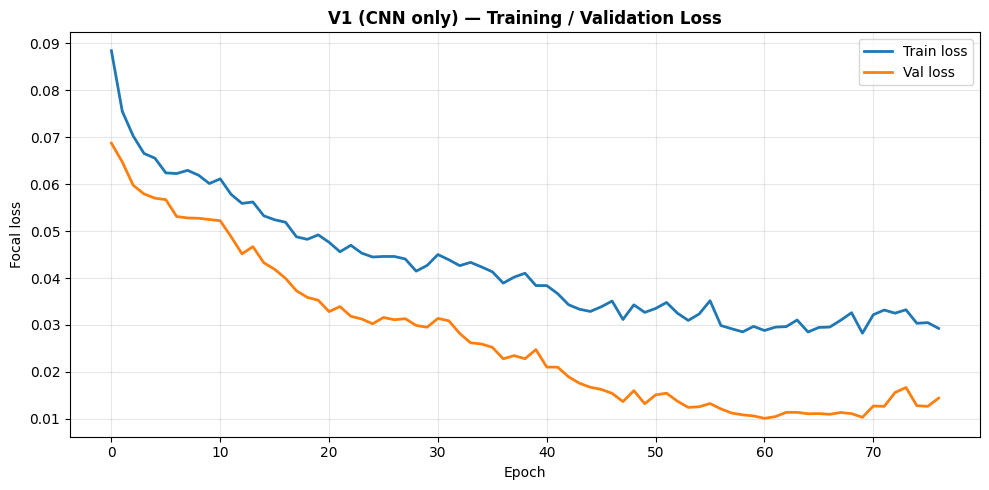

Saved: <repo>/results\Ablation_V1\V1_Loss_Curve.png


In [10]:
plt.figure(figsize=(10,5))
plt.plot(history['train_loss'], label='Train loss', linewidth=2)
plt.plot(history['val_loss'],   label='Val loss',   linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Focal loss')
plt.title('V1 (CNN only) — Training / Validation Loss', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V1_Loss_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7B — Training Accuracy Curve

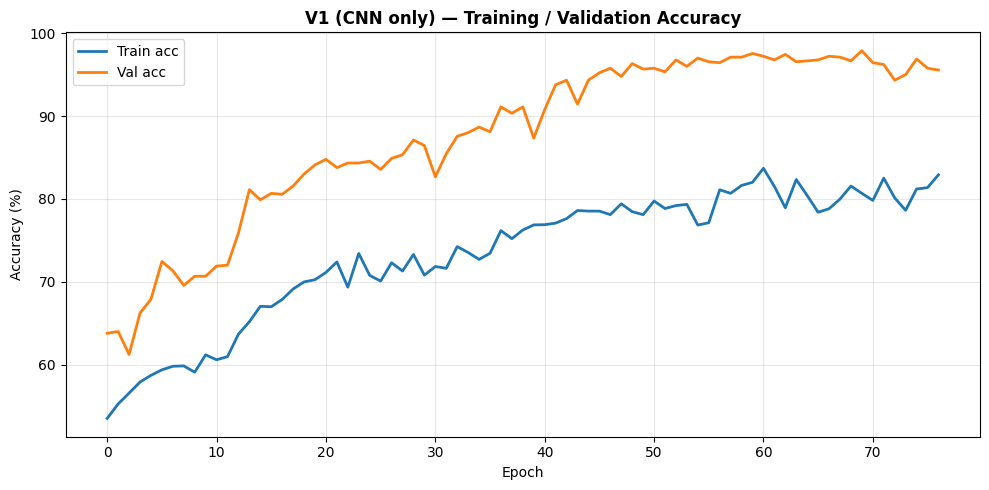

Saved: <repo>/results\Ablation_V1\V1_Accuracy_Curve.png


In [11]:
plt.figure(figsize=(10,5))
plt.plot([a*100 for a in history['train_acc']], label='Train acc', linewidth=2)
plt.plot([a*100 for a in history['val_acc']],   label='Val acc',   linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)')
plt.title('V1 (CNN only) — Training / Validation Accuracy', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V1_Accuracy_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7C — Validation AUC-ROC Curve

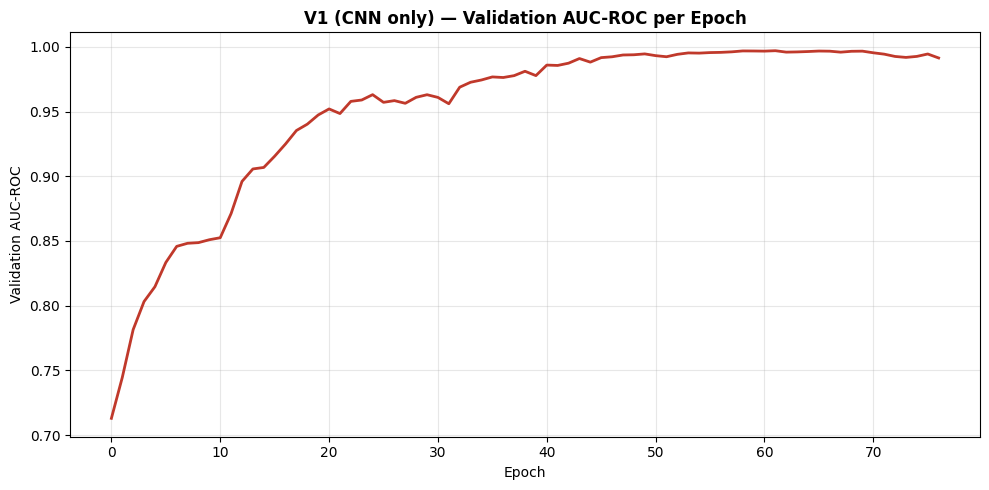

Saved: <repo>/results\Ablation_V1\V1_Validation_AUC_Curve.png


In [12]:
plt.figure(figsize=(10,5))
plt.plot(history['val_auc'], color='#c0392b', linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Validation AUC-ROC')
plt.title('V1 (CNN only) — Validation AUC-ROC per Epoch', fontweight='bold')
plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V1_Validation_AUC_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7D — Confusion Matrix (TTA×5)

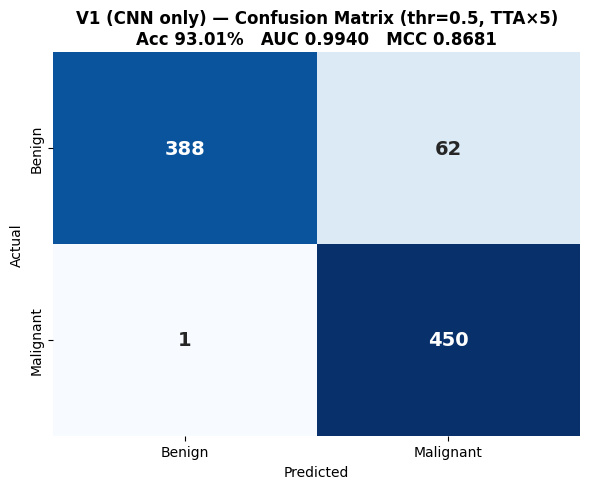

Saved: <repo>/results\Ablation_V1\V1_Confusion_Matrix.png


In [13]:
cm = confusion_matrix(all_labels_test, all_preds_test)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=False, annot_kws={'size':14, 'weight':'bold'})
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'V1 (CNN only) — Confusion Matrix (thr=0.5, TTA×5)\n'
          f'Acc {acc_tta*100:.2f}%   AUC {auc_tta:.4f}   MCC {mcc_tta:.4f}',
          fontweight='bold')
plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V1_Confusion_Matrix.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7E — ROC Curve

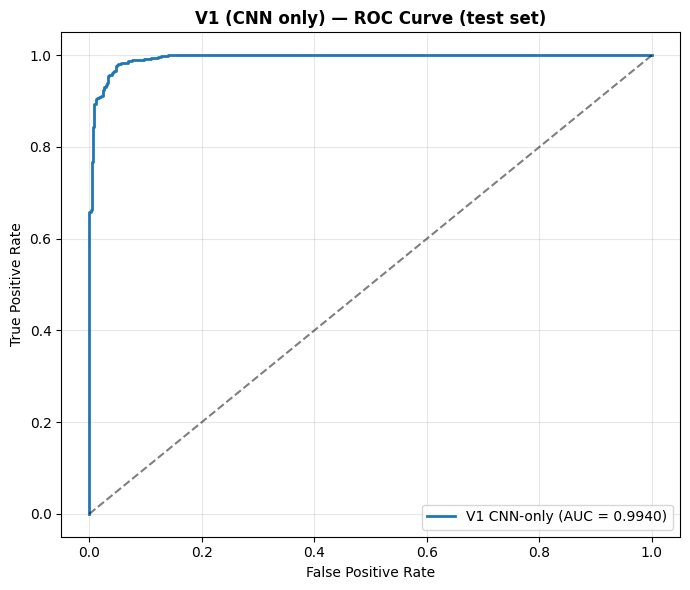

Saved: <repo>/results\Ablation_V1\V1_ROC_Curve.png


In [14]:
plt.figure(figsize=(7,6))
plt.plot(v1_fpr_saved, v1_tpr_saved, lw=2, label=f'V1 CNN-only (AUC = {v1_auc_saved:.4f})')
plt.plot([0,1],[0,1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('V1 (CNN only) — ROC Curve (test set)', fontweight='bold')
plt.legend(loc='lower right'); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V1_ROC_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7F — Precision-Recall Curve

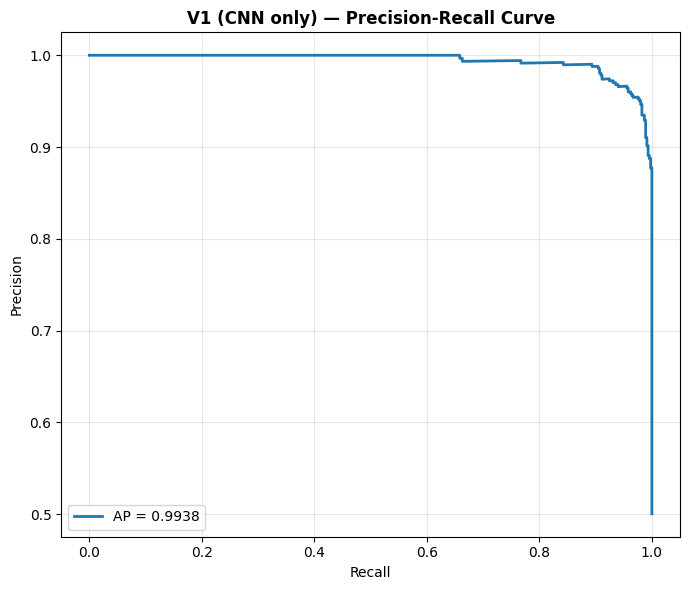

Saved: <repo>/results\Ablation_V1\V1_PR_Curve.png


In [15]:
prec, rec, _ = precision_recall_curve(all_labels_test, all_probs_test)
ap = average_precision_score(all_labels_test, all_probs_test)
plt.figure(figsize=(7,6))
plt.plot(rec, prec, lw=2, label=f'AP = {ap:.4f}')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('V1 (CNN only) — Precision-Recall Curve', fontweight='bold')
plt.legend(loc='lower left'); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V1_PR_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 8 — Final Performance Summary

In [16]:
print('=' * 60)
print(f'  V1 (CNN only) — Final Performance')
print('=' * 60)
print(f'  Test accuracy (TTA×5) : {acc_tta*100:.2f}%')
print(f'  Test AUC-ROC          : {auc_tta:.4f}')
print(f'  MCC                   : {mcc_tta:.4f}')
print(f'  F1                    : {f1_tta:.4f}')
print(f'  Sensitivity           : {sens_tta*100:.2f}%')
print(f'  Specificity           : {spec_tta*100:.2f}%')
print(f'  Best val AUC (epoch)  : {ckpt["best_auc"]:.4f}  (epoch {ckpt["epoch"]})')
print()
print('  Design summary:')
print(f'    Backbone         : EfficientNet-B4 (blocks 0-4 frozen, 5-7 tuned)')
print(f'    CNN proj dim     : {CONFIG["cnn_proj_dim"]}')
print(f'    Head hidden dim  : {CONFIG["head_hidden_dim"]}')
print(f'    Graph branches   : NONE (this is the CNN-only baseline)')
print(f'    Fusion gate      : NONE')
print(f'    Epochs / patience: {CONFIG["num_epochs"]} / {CONFIG["patience"]}   (matched to Hybrid)')
print()
print('  All plots saved as PNG (600 DPI) in:', CONFIG['output_dir'])
print('    V1_Loss_Curve.png')
print('    V1_Accuracy_Curve.png')
print('    V1_Validation_AUC_Curve.png')
print('    V1_Confusion_Matrix.png')
print('    V1_ROC_Curve.png')
print('    V1_PR_Curve.png')
print('=' * 60)


  V1 (CNN only) — Final Performance
  Test accuracy (TTA×5) : 93.01%
  Test AUC-ROC          : 0.9940
  MCC                   : 0.8681
  F1                    : 0.9346
  Sensitivity           : 99.78%
  Specificity           : 86.22%
  Best val AUC (epoch)  : 0.9970  (epoch 62)

  Design summary:
    Backbone         : EfficientNet-B4 (blocks 0-4 frozen, 5-7 tuned)
    CNN proj dim     : 512
    Head hidden dim  : 128
    Graph branches   : NONE (this is the CNN-only baseline)
    Fusion gate      : NONE
    Epochs / patience: 80 / 15   (matched to Hybrid)

  All plots saved as PNG (600 DPI) in: <repo>/results\Ablation_V1
    V1_Loss_Curve.png
    V1_Accuracy_Curve.png
    V1_Validation_AUC_Curve.png
    V1_Confusion_Matrix.png
    V1_ROC_Curve.png
    V1_PR_Curve.png
